# LAB2 - Bài 2 (Trang 15-16): Adult Income

Đinh Nhật Huyền Nhân - 6451071055 - CQ.64.CNTT

### Chuẩn bị thư viện

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn import tree
from sklearn.naive_bayes import GaussianNB
from sklearn import metrics

### Câu 1: Nhập dữ liệu và cho biết số lượng dữ liệu huấn luyện, kiểm thử

In [2]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# Dữ liệu có khoảng trắng sau dấu phẩy nên cần skipinitialspace=True
train_data = pd.read_csv('data/adult.data.csv', skipinitialspace=True)
test_data = pd.read_csv('data/adult.test.csv', skipinitialspace=True)
print('Number of training data:', len(train_data))
print('Number of test data:', len(test_data))

Đinh Nhật Huyền Nhân - 6451071055
Number of training data: 32561
Number of test data: 16281


### Câu 2: Tiền xử lý dữ liệu

In [3]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# Xóa những dòng chứa dữ liệu trống (ký hiệu bằng dấu '?')
train_data = train_data.replace('?', np.nan).dropna()
test_data = test_data.replace('?', np.nan).dropna()
print('Number of training data:', len(train_data))
print('Number of test data:', len(test_data))

# Xóa cột fnlwgt vì cột này không có trong dữ liệu kiểm thử
train_data = train_data.drop('fnlwgt', axis=1)

# Nối hai phần dữ liệu để phục vụ các bước tiếp theo
n_train = len(train_data)
data = pd.concat([train_data, test_data], ignore_index=True)
data.info()

Đinh Nhật Huyền Nhân - 6451071055
Number of training data: 30162
Number of test data: 15060
<class 'pandas.DataFrame'>
RangeIndex: 45222 entries, 0 to 45221
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             45222 non-null  int64
 1   workclass       45222 non-null  str  
 2   education       45222 non-null  str  
 3   education-num   45222 non-null  int64
 4   marital-status  45222 non-null  str  
 5   occupation      45222 non-null  str  
 6   relationship    45222 non-null  str  
 7   race            45222 non-null  str  
 8   sex             45222 non-null  str  
 9   capital-gain    45222 non-null  int64
 10  capital-loss    45222 non-null  int64
 11  hours-per-week  45222 non-null  int64
 12  native-country  45222 non-null  str  
 13  income          45222 non-null  str  
dtypes: int64(5), str(9)
memory usage: 4.8 MB


### Câu 3: Khảo sát độ tương đồng giữa các cột bằng công thức Pearson

Đinh Nhật Huyền Nhân - 6451071055


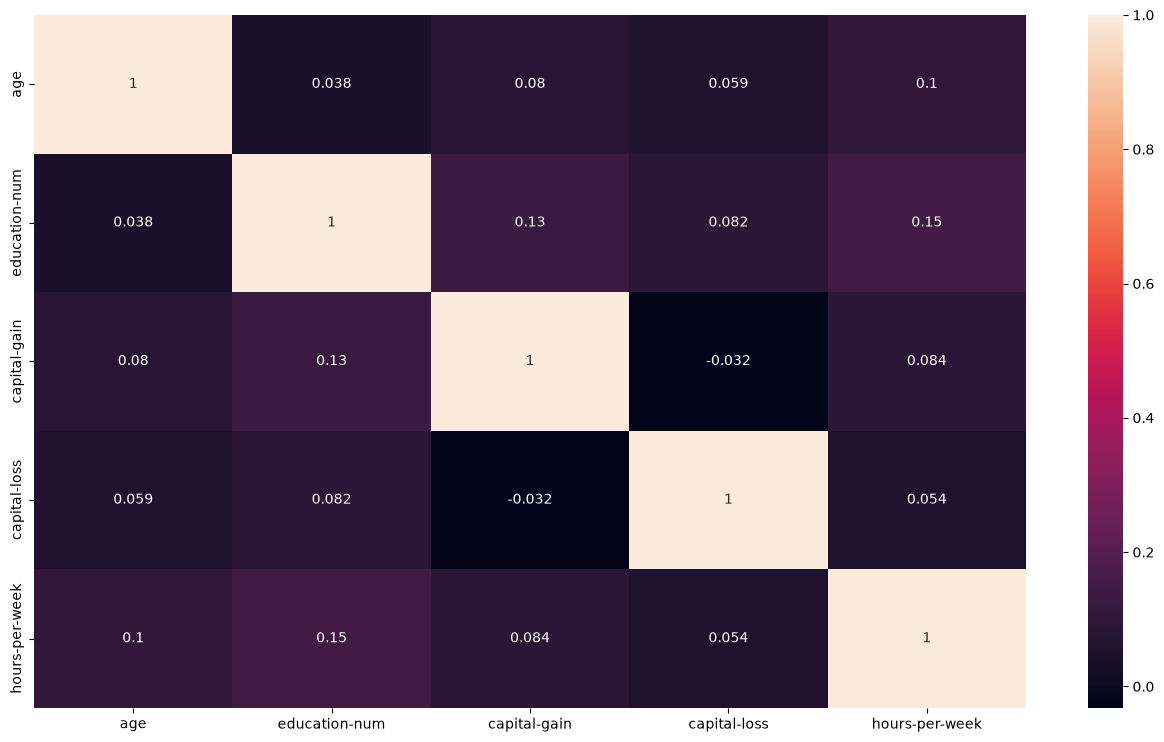

Các cặp có |r| >= 0.8: không có
Cặp tương quan mạnh nhất: education-num - hours-per-week = 0.146


In [4]:
print("Đinh Nhật Huyền Nhân - 6451071055")
corr = data.corr(method='pearson', numeric_only=True)
plt.figure(figsize=(16, 9))
sns.heatmap(corr, annot=True)
plt.show()

# Liệt kê các cặp thuộc tính có |r| >= 0.8 (không xét thuộc tính quyết định)
threshold = 0.8
pairs = corr.drop(columns='income', errors='ignore').drop(index='income', errors='ignore')
high_corr = [(a, b, round(pairs.loc[a, b], 3))
             for i, a in enumerate(pairs.columns)
             for b in pairs.columns[i + 1:]
             if abs(pairs.loc[a, b]) >= threshold]
print('Các cặp có |r| >= 0.8:', high_corr if high_corr else 'không có')

# Cặp tương quan mạnh nhất để đối chiếu với ngưỡng
strongest = max(((a, b, pairs.loc[a, b])
                 for i, a in enumerate(pairs.columns)
                 for b in pairs.columns[i + 1:]), key=lambda t: abs(t[2]))
print('Cặp tương quan mạnh nhất:', strongest[0], '-', strongest[1], '=', round(strongest[2], 3))

**Nhận xét:** Không có cặp thuộc tính nào có |r| ≥ 0,8. Cặp tương quan mạnh nhất là education-num và hours-per-week với r = 0,146, rất thấp, nên không cần loại bỏ cột nào.

### Câu 4: Tách thuộc tính bình thường và thuộc tính quyết định

In [5]:
print("Đinh Nhật Huyền Nhân - 6451071055")
features = data.drop('income', axis=1)
labels = data['income']
print('features:', features.shape)
print('labels:', labels.shape)
print(labels.value_counts().sort_index().to_string())

Đinh Nhật Huyền Nhân - 6451071055
features: (45222, 13)
labels: (45222,)
income
<=50K    34014
>50K     11208


### Câu 5: Chuyển các cột không phải dạng số về one-hot vector

In [6]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# Chỉ lấy cột không phải dạng số: np.number bao gồm cả int64 và float64
non_numeric = features.select_dtypes(exclude=[np.number]).columns
print('Các cột không phải dạng số:', list(non_numeric))
features_onehot = pd.get_dummies(features, columns=non_numeric, dtype=int)
print('Kích thước sau khi chuyển đổi:', features_onehot.shape)
features_onehot.head()

Đinh Nhật Huyền Nhân - 6451071055
Các cột không phải dạng số: ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']
Kích thước sau khi chuyển đổi: (45222, 103)


,age,education-num,capital-gain,capital-loss,hours-per-week,workclass_Federal-gov,workclass_Local-gov,workclass_Private,workclass_Self-emp-inc,workclass_Self-emp-not-inc,...,native-country_Portugal,native-country_Puerto-Rico,native-country_Scotland,native-country_South,native-country_Taiwan,native-country_Thailand,native-country_Trinadad&Tobago,native-country_United-States,native-country_Vietnam,native-country_Yugoslavia
0,39,13,2174,0,40,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
1,50,13,0,0,13,0,0,0,0,1,...,0,0,0,0,0,0,0,1,0,0
2,38,9,0,0,40,0,0,1,0,0,...,0,0,0,0,0,0,0,1,0,0
3,53,7,0,0,40,0,0,1,0,0,...,0,0,0,0,0,0,0,1,0,0
4,28,13,0,0,40,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0


### Câu 6: Tách dữ liệu huấn luyện và kiểm thử

In [7]:
print("Đinh Nhật Huyền Nhân - 6451071055")
X_train = features_onehot[:n_train]
X_test = features_onehot[n_train:]
y_train = labels[:n_train]
y_test = labels[n_train:]
print('Number of training data:', len(X_train))
print('Number of test data:', len(X_test))

Đinh Nhật Huyền Nhân - 6451071055
Number of training data: 30162
Number of test data: 15060


**Nhận xét:** Hai phần được tách theo đúng số dòng ban đầu: 30162 dòng huấn luyện và 15060 dòng kiểm thử.

### Câu 7: Xây dựng cây ID3 và kiểm thử bằng ma trận nhầm lẫn

In [8]:
print("Đinh Nhật Huyền Nhân - 6451071055")
id3 = tree.DecisionTreeClassifier(criterion="entropy", random_state=0)
# Train Decision Tree Classifier
id3.fit(X_train, y_train)
print('Độ sâu của cây:', id3.get_depth(), '- Số nút lá:', id3.get_n_leaves())

Đinh Nhật Huyền Nhân - 6451071055


Độ sâu của cây: 51 - Số nút lá: 5327


In [9]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# Predict the response for test dataset
id3_pred = id3.predict(X_test)

# Model Accuracy, how often is the classifier correct?
id3_score = metrics.accuracy_score(y_test, id3_pred)
print("Accuracy:", id3_score)
print("Report:", metrics.classification_report(y_test, id3_pred, zero_division=0))

Đinh Nhật Huyền Nhân - 6451071055
Accuracy: 0.8175298804780876
Report:               precision    recall  f1-score   support

       <=50K       0.88      0.88      0.88     11360
        >50K       0.63      0.62      0.62      3700

    accuracy                           0.82     15060
   macro avg       0.75      0.75      0.75     15060
weighted avg       0.82      0.82      0.82     15060



Đinh Nhật Huyền Nhân - 6451071055
[[10031  1329]
 [ 1419  2281]]


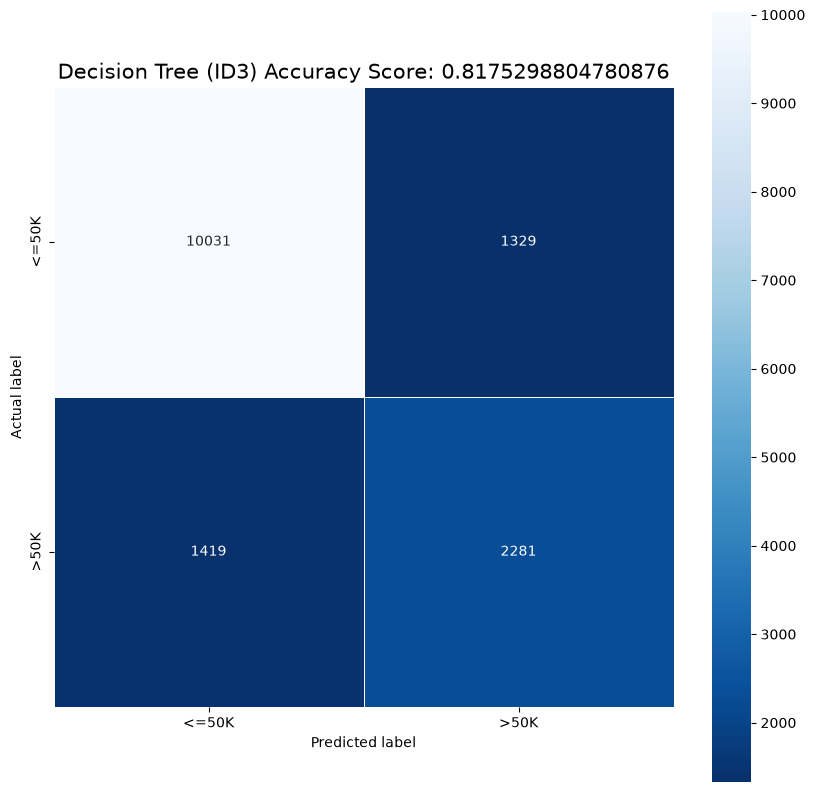

In [10]:
print("Đinh Nhật Huyền Nhân - 6451071055")
id3_cm = metrics.confusion_matrix(y_test, id3_pred, labels=id3.classes_)
print(id3_cm)

plt.figure(figsize=(10, 10))
sns.heatmap(id3_cm, annot=True, fmt="d", linewidths=.5, square=True, cmap='Blues_r',
            xticklabels=id3.classes_, yticklabels=id3.classes_)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title('Decision Tree (ID3) Accuracy Score: {0}'.format(id3_score), size=15)
plt.show()

Đinh Nhật Huyền Nhân - 6451071055


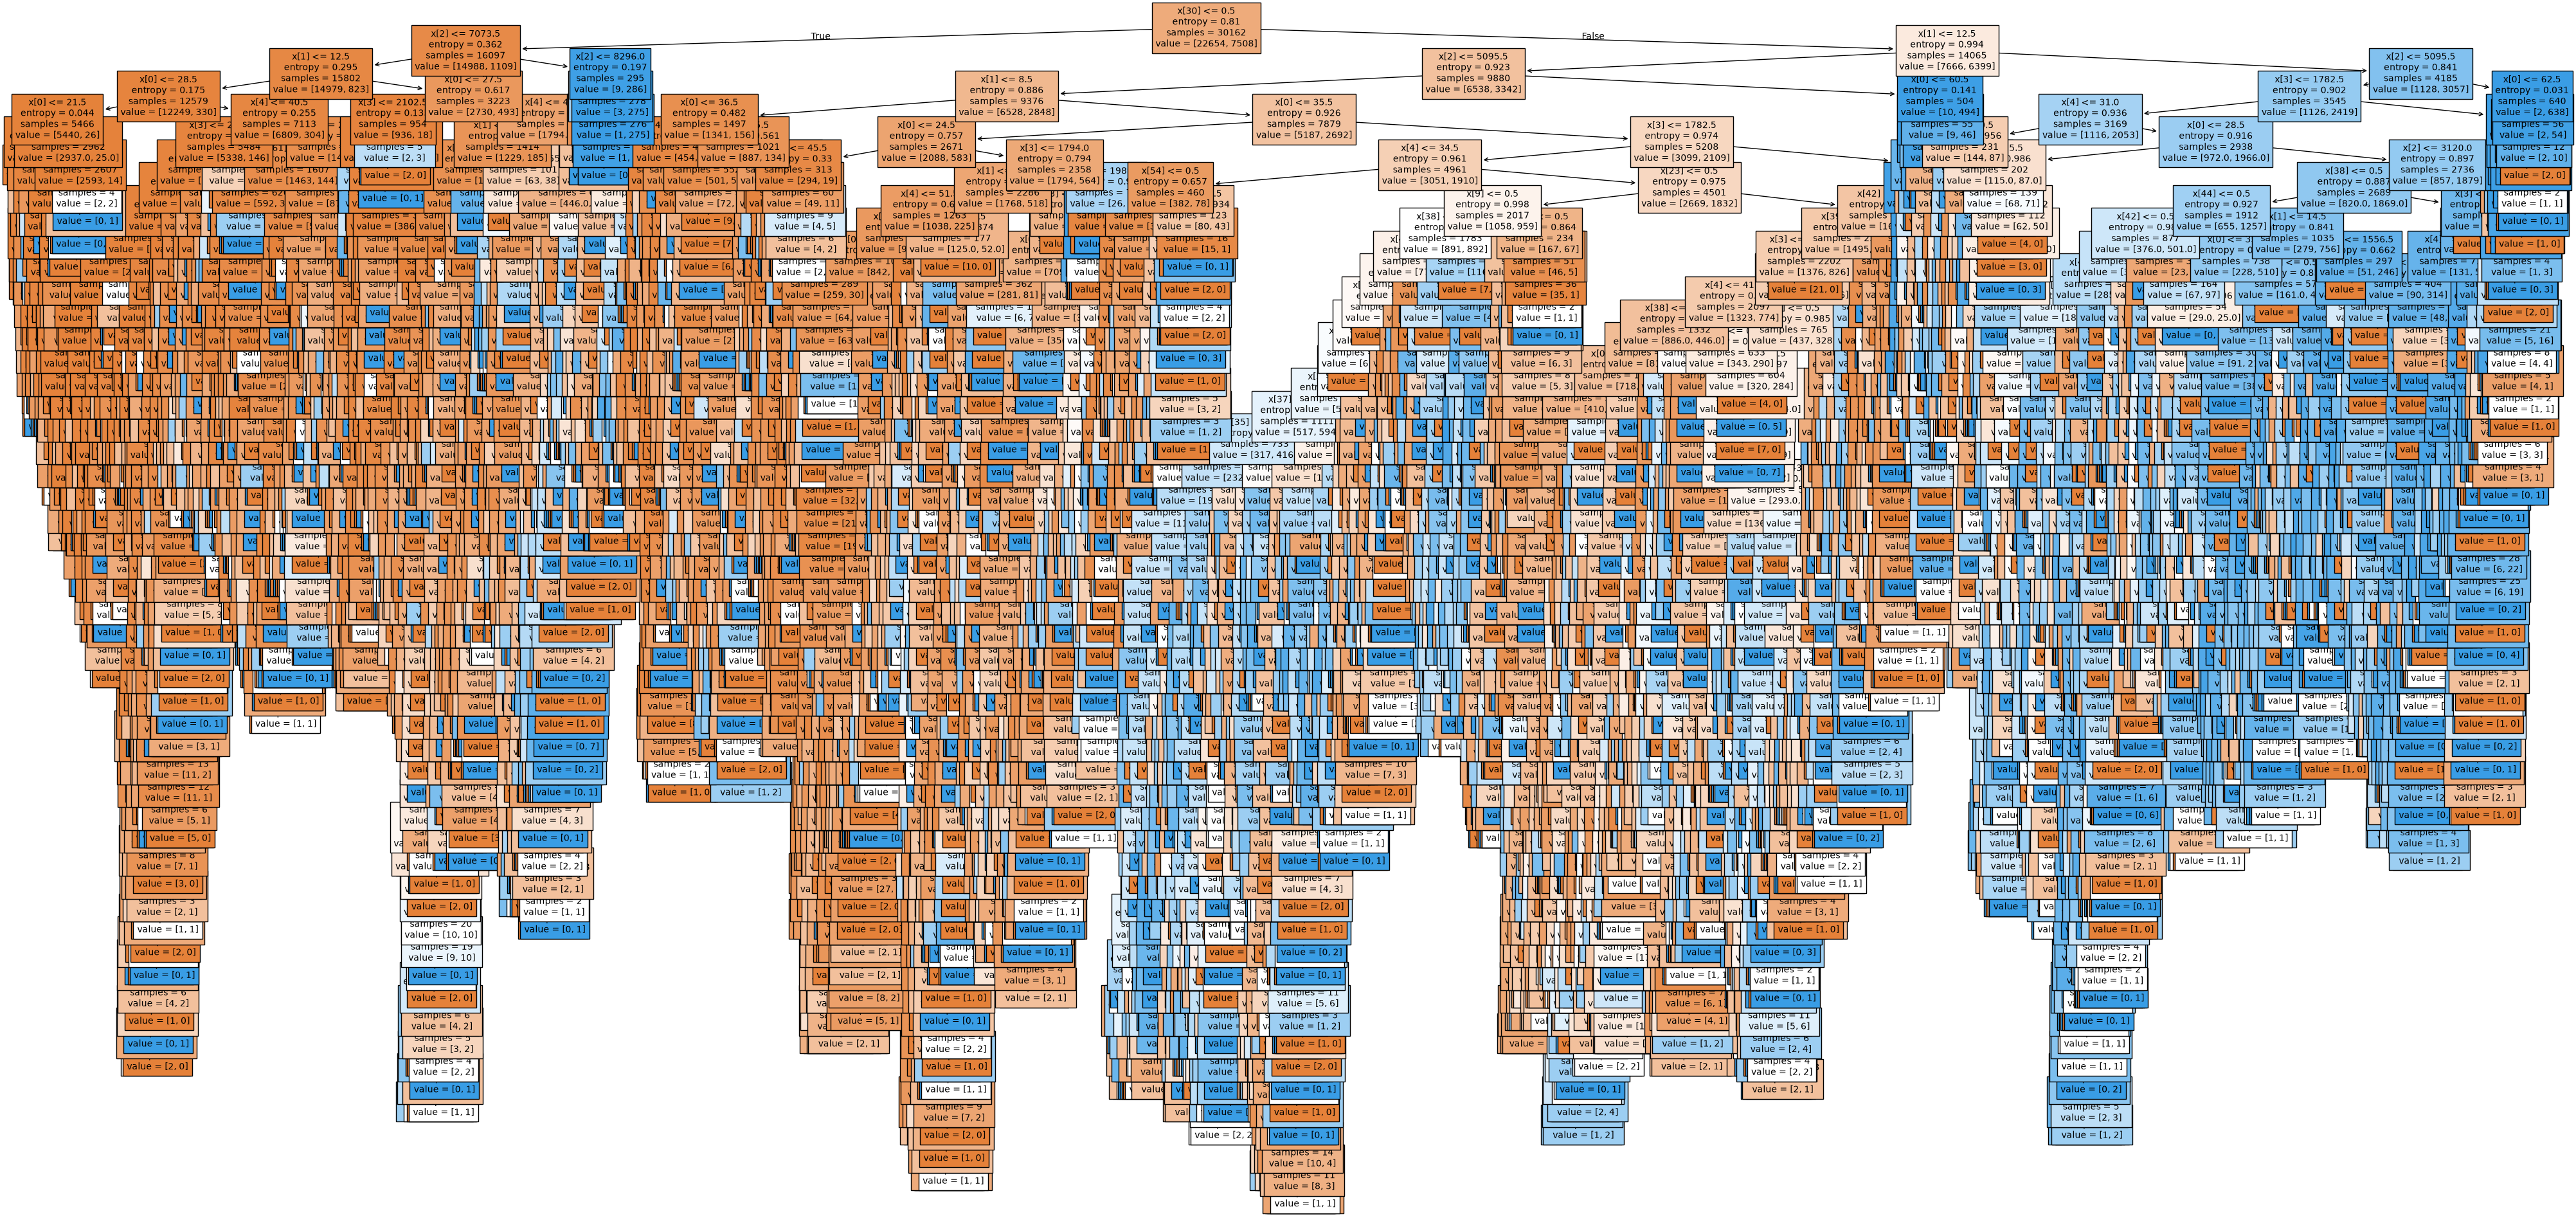

In [11]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# Biểu diễn toàn bộ cây và lưu vào file ảnh
fig, ax = plt.subplots(figsize=(50, 24))
tree.plot_tree(id3, filled=True, fontsize=10)
plt.savefig('outputs/bai2_id3_tree', dpi=100)
plt.show()

Đinh Nhật Huyền Nhân - 6451071055


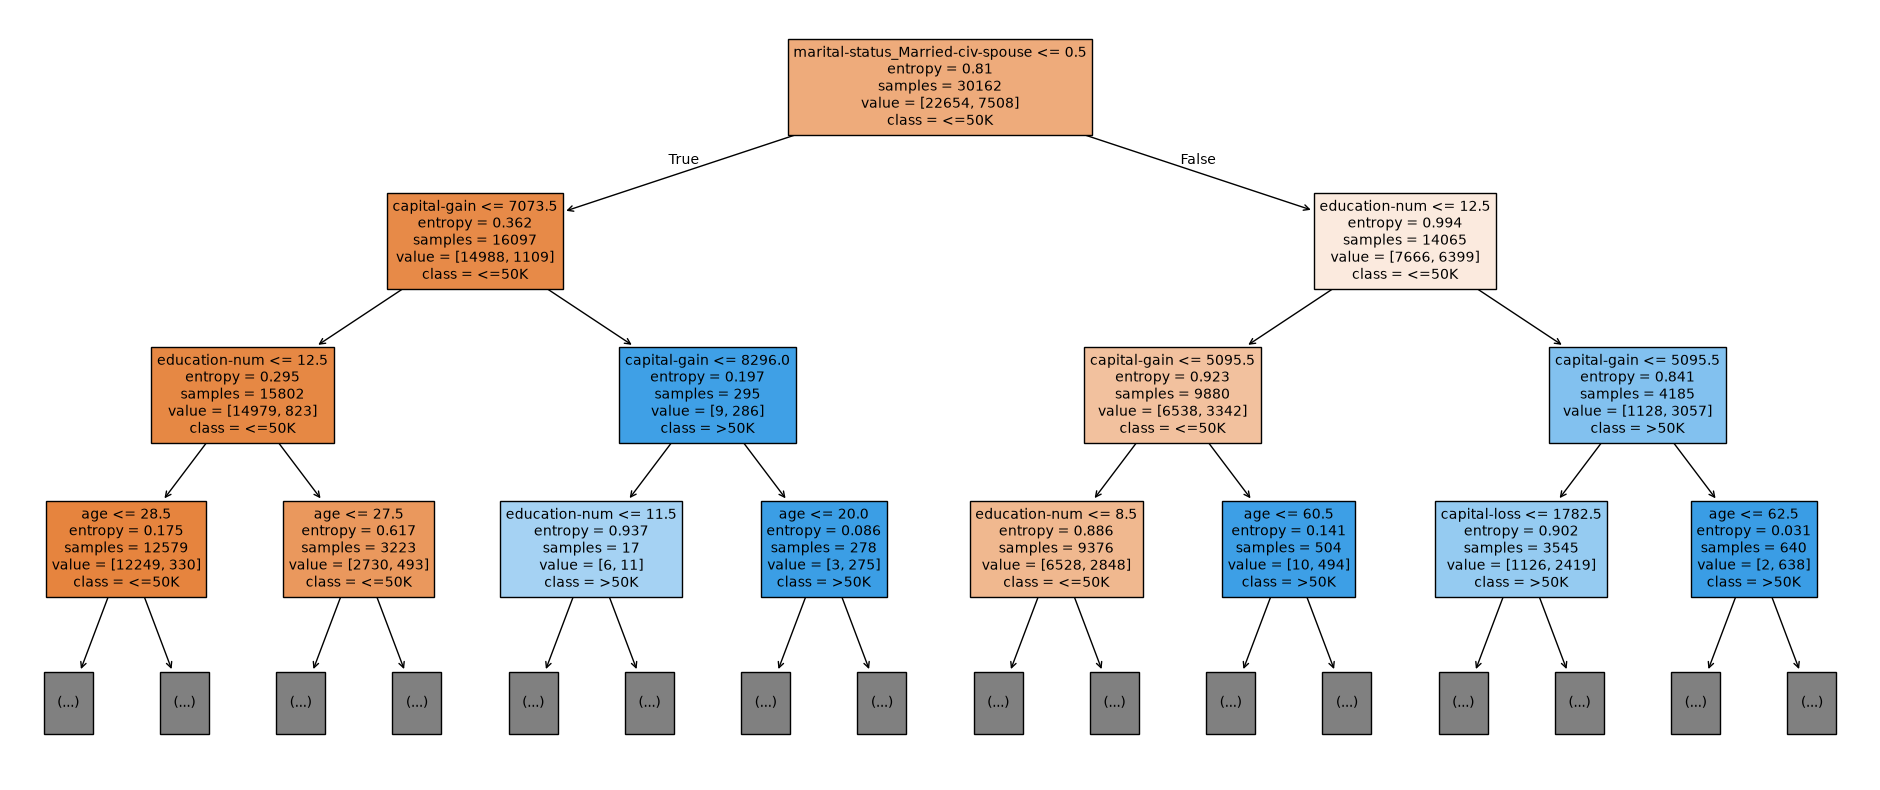

In [12]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# Cây đầy đủ rất lớn nên vẽ thêm 3 tầng đầu với tên thuộc tính để dễ đọc
fig, ax = plt.subplots(figsize=(24, 10))
tree.plot_tree(id3, max_depth=3, feature_names=list(X_train.columns),
               class_names=[str(c) for c in id3.classes_], filled=True, fontsize=10)
plt.savefig('outputs/bai2_id3_tree_top3', dpi=100)
plt.show()

### Câu 8: Xây dựng cây CART (criterion='gini')

In [13]:
print("Đinh Nhật Huyền Nhân - 6451071055")
cart = tree.DecisionTreeClassifier(criterion="gini", random_state=0)
# Train Decision Tree Classifier
cart.fit(X_train, y_train)
print('Độ sâu của cây:', cart.get_depth(), '- Số nút lá:', cart.get_n_leaves())

Đinh Nhật Huyền Nhân - 6451071055
Độ sâu của cây: 46 - Số nút lá: 5331


In [14]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# Predict the response for test dataset
cart_pred = cart.predict(X_test)

# Model Accuracy, how often is the classifier correct?
cart_score = metrics.accuracy_score(y_test, cart_pred)
print("Accuracy:", cart_score)
print("Report:", metrics.classification_report(y_test, cart_pred, zero_division=0))

Đinh Nhật Huyền Nhân - 6451071055
Accuracy: 0.8122841965471448
Report:               precision    recall  f1-score   support

       <=50K       0.87      0.88      0.88     11360
        >50K       0.62      0.60      0.61      3700

    accuracy                           0.81     15060
   macro avg       0.75      0.74      0.74     15060
weighted avg       0.81      0.81      0.81     15060



Đinh Nhật Huyền Nhân - 6451071055
[[10009  1351]
 [ 1476  2224]]


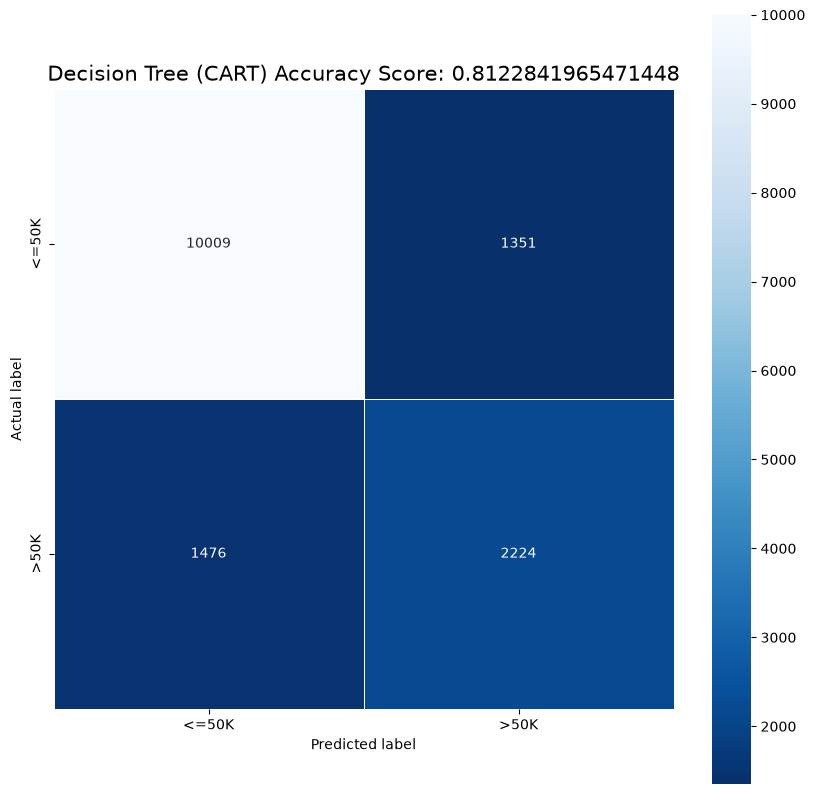

In [15]:
print("Đinh Nhật Huyền Nhân - 6451071055")
cart_cm = metrics.confusion_matrix(y_test, cart_pred, labels=cart.classes_)
print(cart_cm)

plt.figure(figsize=(10, 10))
sns.heatmap(cart_cm, annot=True, fmt="d", linewidths=.5, square=True, cmap='Blues_r',
            xticklabels=cart.classes_, yticklabels=cart.classes_)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title('Decision Tree (CART) Accuracy Score: {0}'.format(cart_score), size=15)
plt.show()

Đinh Nhật Huyền Nhân - 6451071055


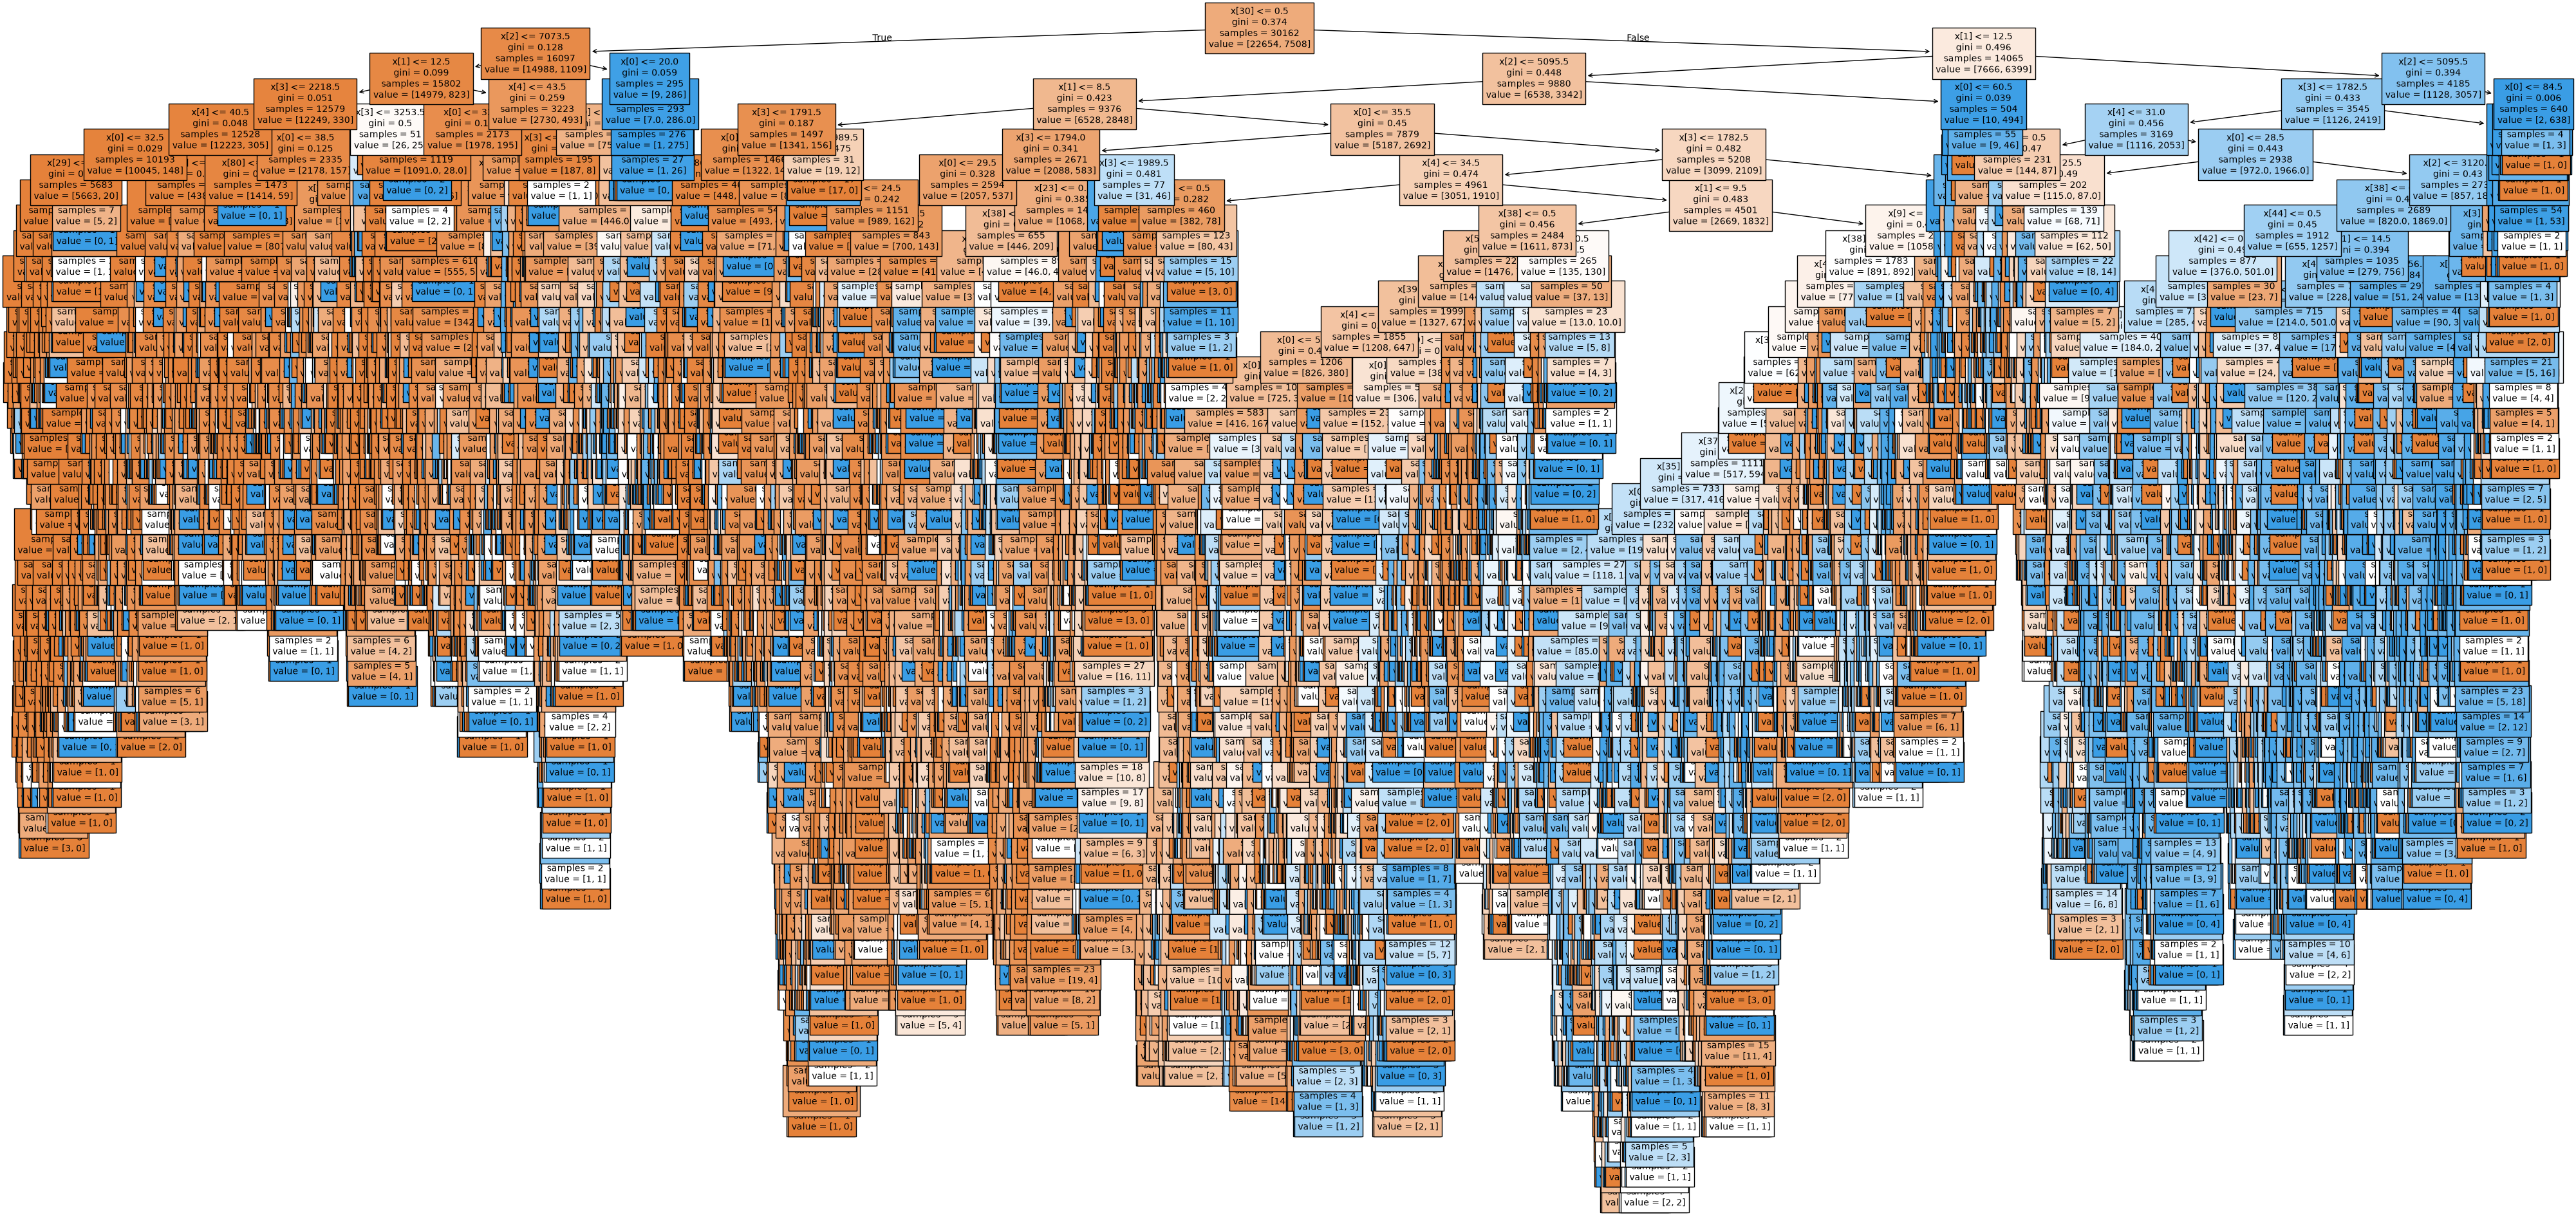

In [16]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# Biểu diễn toàn bộ cây và lưu vào file ảnh
fig, ax = plt.subplots(figsize=(50, 24))
tree.plot_tree(cart, filled=True, fontsize=10)
plt.savefig('outputs/bai2_cart_tree', dpi=100)
plt.show()

Đinh Nhật Huyền Nhân - 6451071055


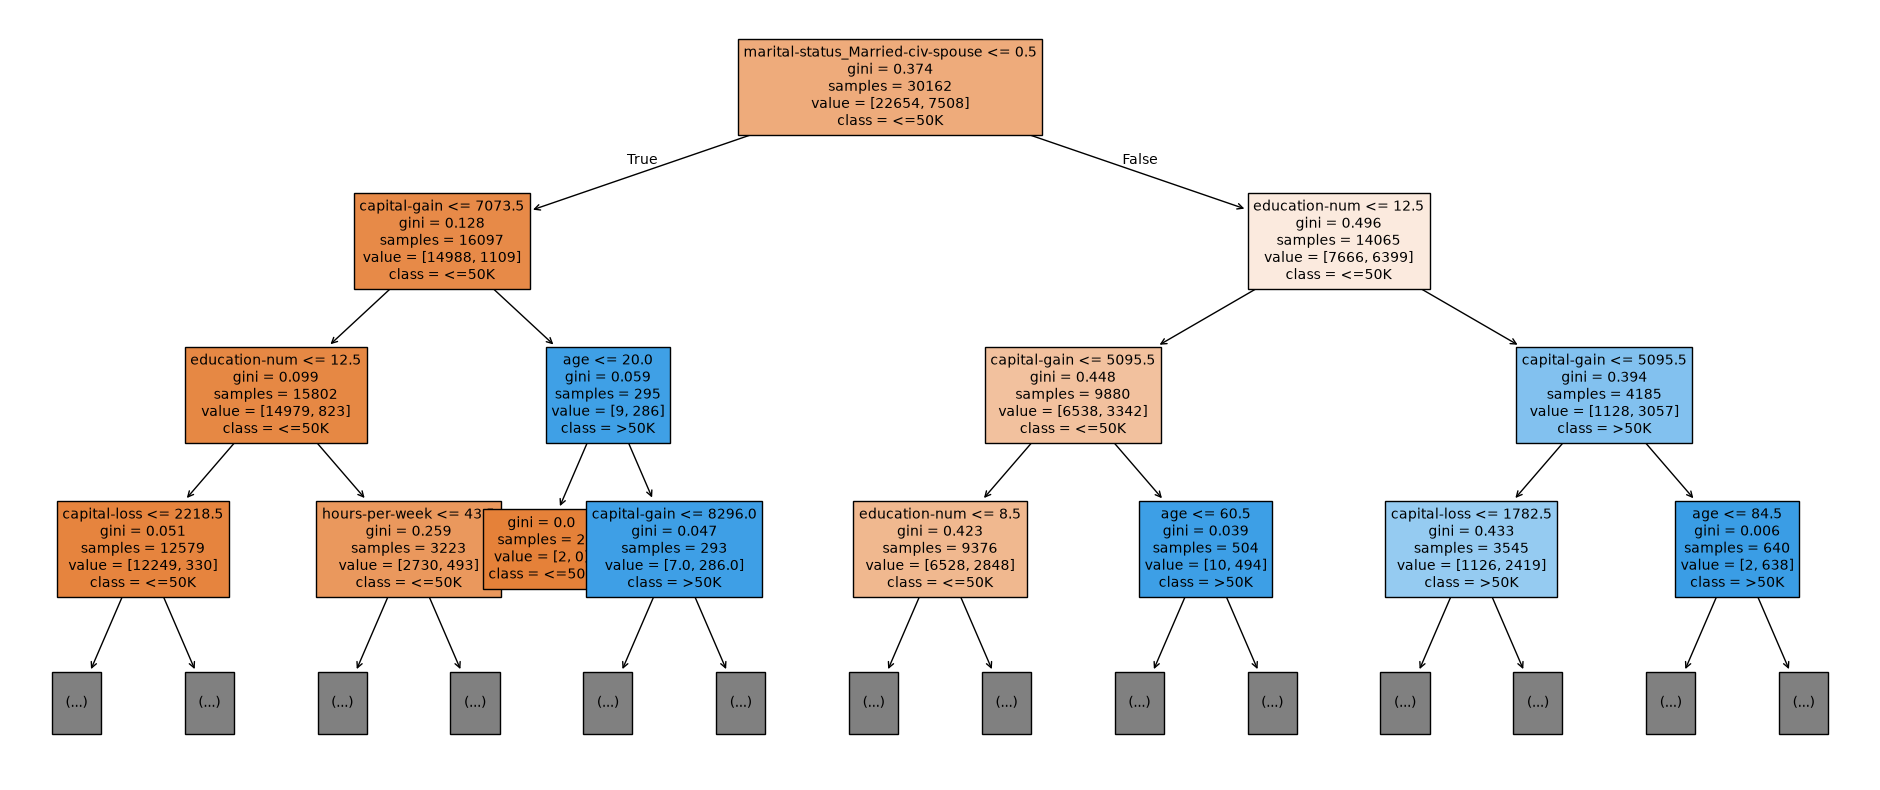

In [17]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# Cây đầy đủ rất lớn nên vẽ thêm 3 tầng đầu với tên thuộc tính để dễ đọc
fig, ax = plt.subplots(figsize=(24, 10))
tree.plot_tree(cart, max_depth=3, feature_names=list(X_train.columns),
               class_names=[str(c) for c in cart.classes_], filled=True, fontsize=10)
plt.savefig('outputs/bai2_cart_tree_top3', dpi=100)
plt.show()

### Câu 9: Xây dựng mô hình Naïve Bayes

In [18]:
print("Đinh Nhật Huyền Nhân - 6451071055")
gnb = GaussianNB()
bayes_pred = gnb.fit(X_train, y_train).predict(X_test)

Đinh Nhật Huyền Nhân - 6451071055


In [19]:
print("Đinh Nhật Huyền Nhân - 6451071055")
# Model Accuracy, how often is the classifier correct?
bayes_score = metrics.accuracy_score(y_test, bayes_pred)
print("Accuracy:", bayes_score)
print("Report:", metrics.classification_report(y_test, bayes_pred, zero_division=0))

Đinh Nhật Huyền Nhân - 6451071055
Accuracy: 0.8029216467463479
Report:               precision    recall  f1-score   support

       <=50K       0.93      0.80      0.86     11360
        >50K       0.57      0.82      0.67      3700

    accuracy                           0.80     15060
   macro avg       0.75      0.81      0.76     15060
weighted avg       0.84      0.80      0.81     15060



Đinh Nhật Huyền Nhân - 6451071055
[[9073 2287]
 [ 681 3019]]


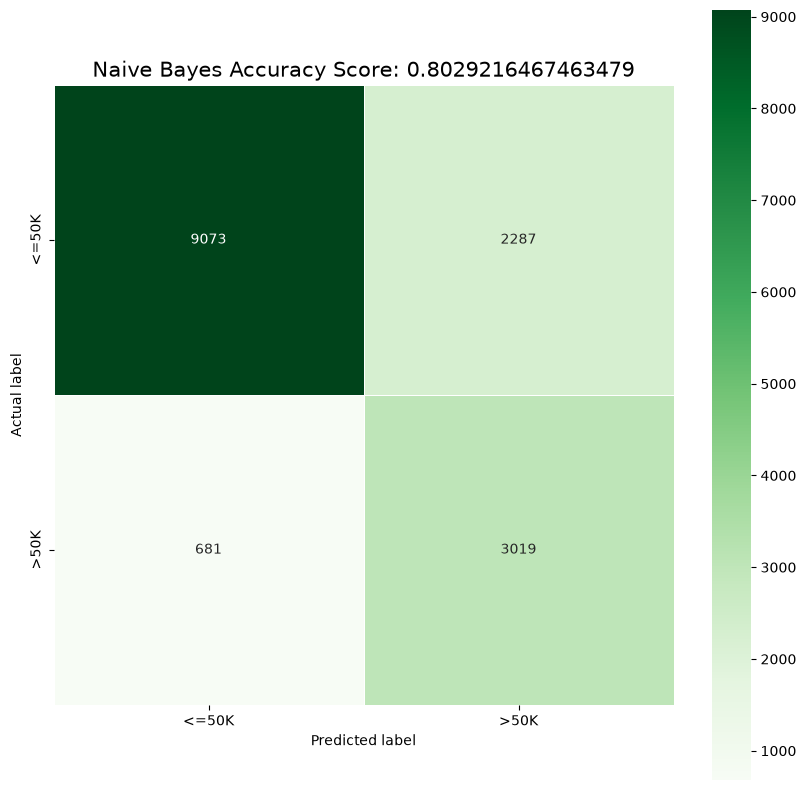

In [20]:
print("Đinh Nhật Huyền Nhân - 6451071055")
bayes_cm = metrics.confusion_matrix(y_test, bayes_pred, labels=gnb.classes_)
print(bayes_cm)

plt.figure(figsize=(10, 10))
sns.heatmap(bayes_cm, annot=True, fmt="d", linewidths=.5, square=True, cmap='Greens',
            xticklabels=gnb.classes_, yticklabels=gnb.classes_)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.title('Naive Bayes Accuracy Score: {0}'.format(bayes_score), size=15)
plt.show()

### Câu 10: So sánh kết quả của các mô hình

In [21]:
print("Đinh Nhật Huyền Nhân - 6451071055")
models = {'ID3': (id3, id3_pred), 'CART': (cart, cart_pred), 'Naive Bayes': (gnb, bayes_pred)}
rows = []
for name, (model, pred) in models.items():
    report = metrics.classification_report(y_test, pred, output_dict=True, zero_division=0)
    rows.append({'Model': name,
                 'Train acc': model.score(X_train, y_train),
                 'Test acc': report['accuracy'],
                 'Macro P': report['macro avg']['precision'],
                 'Macro R': report['macro avg']['recall'],
                 'Macro F1': report['macro avg']['f1-score'],
                 'Weighted F1': report['weighted avg']['f1-score']})
print(pd.DataFrame(rows).set_index('Model').round(4).to_string())

classes = sorted(y_test.unique())
print('\nĐộ chính xác (precision) theo từng lớp:')
print(pd.DataFrame({name: metrics.precision_score(y_test, pred, labels=classes, average=None, zero_division=0)
                    for name, (_, pred) in models.items()}, index=classes).round(4).to_string())
print('\nĐộ phủ (recall) theo từng lớp:')
print(pd.DataFrame({name: metrics.recall_score(y_test, pred, labels=classes, average=None, zero_division=0)
                    for name, (_, pred) in models.items()}, index=classes).round(4).to_string())

Đinh Nhật Huyền Nhân - 6451071055


             Train acc  Test acc  Macro P  Macro R  Macro F1  Weighted F1
Model                                                                    
ID3             0.9750    0.8175   0.7540   0.7497    0.7518       0.8168
CART            0.9750    0.8123   0.7468   0.7411    0.7438       0.8112
Naive Bayes     0.8032    0.8029   0.7496   0.8073    0.7649       0.8130

Độ chính xác (precision) theo từng lớp:
          ID3    CART  Naive Bayes
<=50K  0.8761  0.8715       0.9302
>50K   0.6319  0.6221       0.5690

Độ phủ (recall) theo từng lớp:
          ID3    CART  Naive Bayes
<=50K  0.8830  0.8811       0.7987
>50K   0.6165  0.6011       0.8159


**Nhận xét:** ID3 có accuracy kiểm thử cao nhất (0,8175), tiếp theo là CART (0,8123) và Naïve Bayes (0,8029). Tuy nhiên, Naïve Bayes có Macro F1 cao nhất (0,7649 so với 0,7518 của ID3 và 0,7438 của CART) nhờ độ phủ lớp >50K đạt 0,8159, cao hơn hẳn ID3 (0,6165) và CART (0,6011). Đổi lại, độ chính xác lớp >50K của Naïve Bayes thấp hơn (0,5690 so với 0,6319 của ID3). Hai cây bị quá khớp: accuracy huấn luyện 0,9750 nhưng kiểm thử chỉ khoảng 0,81, cây rất lớn (ID3 sâu 51 tầng, 5327 nút lá). Naïve Bayes ổn định hơn (0,8032 và 0,8029). Vì vậy, nên chọn ID3 nếu ưu tiên accuracy chung, và chọn Naïve Bayes nếu cần phát hiện được nhiều người có thu nhập >50K.